In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from pathlib import Path

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create project data folder
Path("../data").mkdir(parents=True, exist_ok=True)

# Number of users
n_users = 10000

# Unique IDs
user_ids = [f"U{i:05d}" for i in range(1, n_users + 1)]

# Randomly assign each user to A or B
groups = np.random.choice(
    ["A", "B"],
    size=n_users,
    p=[0.5, 0.5]
)

# Generate user devices
devices = np.random.choice(
    ["Mobile", "Desktop", "Tablet"],
    size=n_users,
    p=[0.60, 0.30, 0.10]
)

# Generate number of visits
visits = np.random.randint(1, 11, size=n_users)

# Generate clicks
clicks = np.array([
    np.random.binomial(v, 0.30)
    for v in visits
])

# Set illustrative purchase probabilities
purchase_probabilities = np.where(groups == "A", 0.082, 0.097)

# Generate whether each user purchased
purchases = np.random.binomial(
    1,
    purchase_probabilities
)

# Generate revenue only when a purchase occurs
revenue = np.where(
    purchases == 1,
    np.random.gamma(shape=4, scale=300, size=n_users),
    0
)

# Create DataFrame
df = pd.DataFrame({
    "user_id": user_ids,
    "group": groups,
    "device": devices,
    "visits": visits,
    "clicks": clicks,
    "purchases": purchases,
    "revenue": np.round(revenue, 2)
})

# Save dataset
df.to_csv("../data/ab_test_users.csv", index=False)

df.head()

,user_id,group,device,visits,clicks,purchases,revenue
0,U00001,A,Mobile,6,2,0,0.0
1,U00002,B,Mobile,2,0,1,2223.3
2,U00003,B,Mobile,4,1,0,0.0
3,U00004,B,Desktop,7,4,0,0.0
4,U00005,A,Mobile,6,2,0,0.0


In [3]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset shape: (10000, 7)

Column names:
['user_id', 'group', 'device', 'visits', 'clicks', 'purchases', 'revenue']

First five rows:


,user_id,group,device,visits,clicks,purchases,revenue
0,U00001,A,Mobile,6,2,0,0.0
1,U00002,B,Mobile,2,0,1,2223.3
2,U00003,B,Mobile,4,1,0,0.0
3,U00004,B,Desktop,7,4,0,0.0
4,U00005,A,Mobile,6,2,0,0.0



Data types:
user_id          str
group            str
device           str
visits         int32
clicks         int64
purchases      int32
revenue      float64
dtype: object


In [4]:
# Keep a copy of the original data
df_original = df.copy()

# 1. Check missing values
print("Missing values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 3. Check duplicate user IDs
print("Duplicate user IDs:", df["user_id"].duplicated().sum())

# 4. Check group names
print("\nGroup counts:")
print(df["group"].value_counts())

# 5. Check invalid values
print("\nInvalid visits:", (df["visits"] < 1).sum())
print("Invalid clicks:", ((df["clicks"] < 0) | (df["clicks"] > df["visits"])).sum())
print("Invalid purchases:", (~df["purchases"].isin([0, 1])).sum())
print("Negative revenue:", (df["revenue"] < 0).sum())

Missing values:
user_id      0
group        0
device       0
visits       0
clicks       0
purchases    0
revenue      0
dtype: int64

Duplicate rows: 0
Duplicate user IDs: 0

Group counts:
group
A    5076
B    4924
Name: count, dtype: int64

Invalid visits: 0
Invalid clicks: 0
Invalid purchases: 0
Negative revenue: 0


In [5]:
# Remove duplicate user records
df = df.drop_duplicates(subset="user_id").copy()

# Remove records with missing essential fields
required_columns = [
    "user_id", "group", "device",
    "visits", "clicks", "purchases", "revenue"
]

df = df.dropna(subset=required_columns).copy()

# Keep only valid experiment groups
df = df[df["group"].isin(["A", "B"])].copy()

# Keep valid numeric values
df = df[
    (df["visits"] >= 1) &
    (df["clicks"] >= 0) &
    (df["clicks"] <= df["visits"]) &
    (df["purchases"].isin([0, 1])) &
    (df["revenue"] >= 0)
].copy()

# Ensure data types are correct
df["visits"] = df["visits"].astype(int)
df["clicks"] = df["clicks"].astype(int)
df["purchases"] = df["purchases"].astype(int)
df["revenue"] = df["revenue"].astype(float)

print("Cleaning completed.")
print("Final shape:", df.shape)

Cleaning completed.
Final shape: (10000, 7)


In [6]:
df.to_csv("../data/ab_test_users.csv", index=False)

In [7]:
display(df.describe())

,visits,clicks,purchases,revenue
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,5.563700,1.660000,0.094500,116.749352
std,2.848465,1.377603,0.292538,407.154610
min,1.000000,0.000000,0.000000,0.000000
25%,3.000000,1.000000,0.000000,0.000000
50%,6.000000,1.000000,0.000000,0.000000
75%,8.000000,3.000000,0.000000,0.000000
max,10.000000,8.000000,1.000000,4072.730000


group
A    5076
B    4924
Name: count, dtype: int64


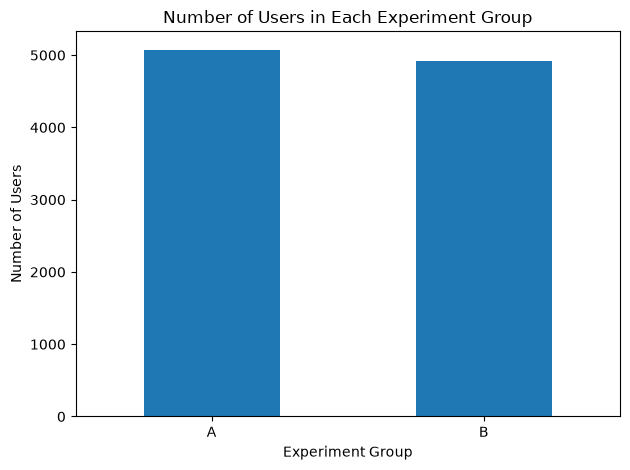

In [8]:
group_counts = df["group"].value_counts().sort_index()

print(group_counts)

group_counts.plot(
    kind="bar",
    title="Number of Users in Each Experiment Group",
    xlabel="Experiment Group",
    ylabel="Number of Users",
    rot=0
)

plt.tight_layout()
plt.show()

group,A,B
device,,
Desktop,1537,1497
Mobile,3020,2925
Tablet,519,502


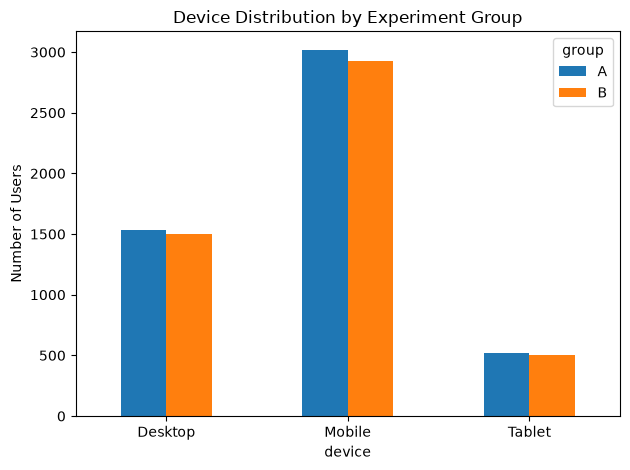

In [9]:
device_distribution = pd.crosstab(
    df["device"],
    df["group"]
)

display(device_distribution)

device_distribution.plot(
    kind="bar",
    title="Device Distribution by Experiment Group",
    ylabel="Number of Users",
    rot=0
)

plt.tight_layout()
plt.show()

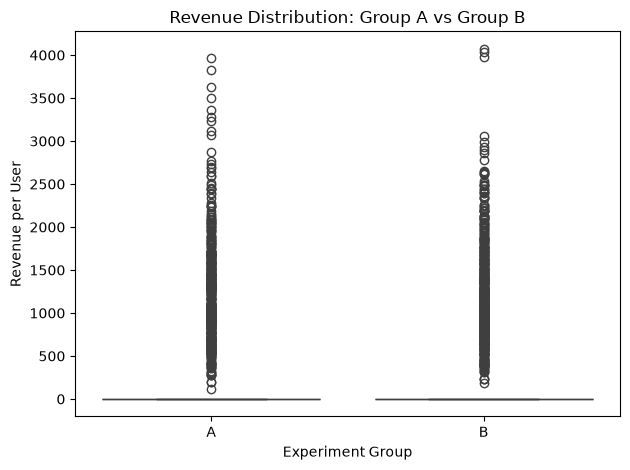

In [10]:
sns.boxplot(
    data=df,
    x="group",
    y="revenue"
)

plt.title("Revenue Distribution: Group A vs Group B")
plt.xlabel("Experiment Group")
plt.ylabel("Revenue per User")

plt.tight_layout()
plt.show()

In [11]:
summary = df.groupby("group").agg(
    total_users=("user_id", "nunique"),
    total_purchases=("purchases", "sum"),
    total_visits=("visits", "sum"),
    total_clicks=("clicks", "sum"),
    total_revenue=("revenue", "sum"),
    average_revenue_per_user=("revenue", "mean"),
    average_visits_per_user=("visits", "mean")
).reset_index()

# Conversion rate = purchasers / users
summary["conversion_rate"] = (
    summary["total_purchases"] / summary["total_users"] * 100
)

# Click-through rate = clicks / visits
summary["click_through_rate"] = (
    summary["total_clicks"] / summary["total_visits"] * 100
)

# Revenue per user
summary["revenue_per_user"] = (
    summary["total_revenue"] / summary["total_users"]
)

display(summary.round(3))

,group,total_users,total_purchases,total_visits,total_clicks,total_revenue,average_revenue_per_user,average_visits_per_user,conversion_rate,click_through_rate,revenue_per_user
0,A,5076,433,28241,8469,540659.18,106.513,5.564,8.530,29.988,106.513
1,B,4924,512,27396,8131,626834.34,127.302,5.564,10.398,29.680,127.302


In [12]:
conversion_a = summary.loc[
    summary["group"] == "A", "conversion_rate"
].iloc[0]

conversion_b = summary.loc[
    summary["group"] == "B", "conversion_rate"
].iloc[0]

absolute_lift = conversion_b - conversion_a

relative_lift = (
    (conversion_b - conversion_a) / conversion_a * 100
    if conversion_a > 0 else np.nan
)

print(f"Group A conversion rate: {conversion_a:.2f}%")
print(f"Group B conversion rate: {conversion_b:.2f}%")
print(f"Absolute lift: {absolute_lift:.2f} percentage points")
print(f"Relative lift: {relative_lift:.2f}%")

Group A conversion rate: 8.53%
Group B conversion rate: 10.40%
Absolute lift: 1.87 percentage points
Relative lift: 21.89%


In [13]:
# Separate users by experiment group
group_a = df[df["group"] == "A"]
group_b = df[df["group"] == "B"]

# Number of users
n_a = len(group_a)
n_b = len(group_b)

# Number of purchasers
x_a = group_a["purchases"].sum()
x_b = group_b["purchases"].sum()

# Observed conversion rates
p_a = x_a / n_a
p_b = x_b / n_b

# Pooled conversion rate under the null hypothesis
p_pooled = (x_a + x_b) / (n_a + n_b)

# Standard error under the null hypothesis
standard_error = np.sqrt(
    p_pooled * (1 - p_pooled) *
    (1 / n_a + 1 / n_b)
)

# Z statistic
z_statistic = (p_b - p_a) / standard_error

# Two-sided p-value
p_value = 2 * stats.norm.sf(abs(z_statistic))

alpha = 0.05

print(f"Group A: {x_a}/{n_a} purchasers ({p_a*100:.2f}%)")
print(f"Group B: {x_b}/{n_b} purchasers ({p_b*100:.2f}%)")
print(f"Z statistic: {z_statistic:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Significance level: {alpha}")

Group A: 433/5076 purchasers (8.53%)
Group B: 512/4924 purchasers (10.40%)
Z statistic: 3.1920
P-value: 0.001413
Significance level: 0.05


In [15]:
if p_value < alpha:
    print("Result: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("Result: No statistically significant difference detected.")
    print("Fail to reject the null hypothesis.")

Result: Statistically significant difference.
Reject the null hypothesis.


In [16]:
# Difference in observed conversion proportions
difference = p_b - p_a

# Standard error for the difference
se_difference = np.sqrt(
    (p_a * (1 - p_a) / n_a) +
    (p_b * (1 - p_b) / n_b)
)

# 95% confidence interval
lower = difference - 1.96 * se_difference
upper = difference + 1.96 * se_difference

print(f"Observed lift: {difference * 100:.2f} percentage points")
print(
    f"95% confidence interval: "
    f"{lower * 100:.2f} to {upper * 100:.2f} percentage points"
)

Observed lift: 1.87 percentage points
95% confidence interval: 0.72 to 3.02 percentage points


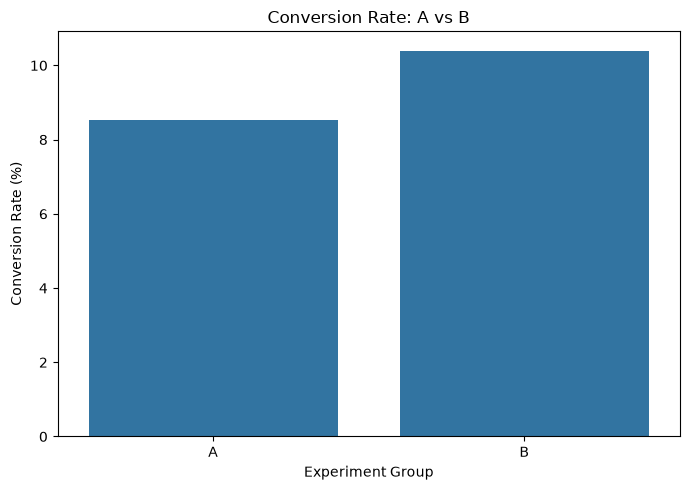

In [17]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=summary,
    x="group",
    y="conversion_rate"
)

plt.title("Conversion Rate: A vs B")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate (%)")

plt.tight_layout()
plt.savefig("../data/conversion_comparison.png", dpi=150)
plt.show()

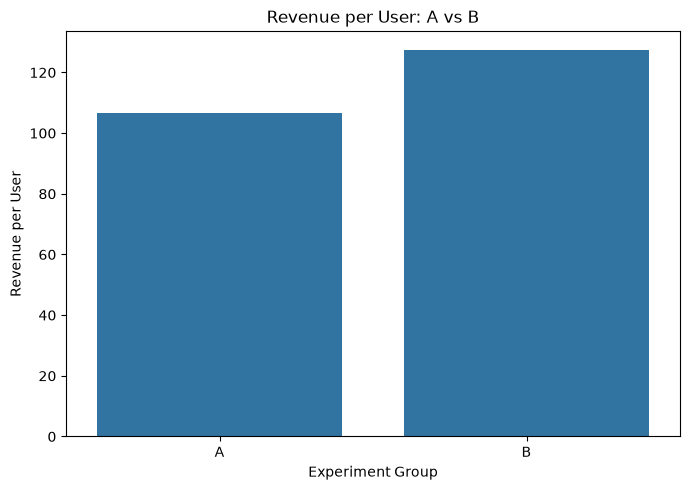

In [18]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=summary,
    x="group",
    y="revenue_per_user"
)

plt.title("Revenue per User: A vs B")
plt.xlabel("Experiment Group")
plt.ylabel("Revenue per User")

plt.tight_layout()
plt.savefig("../data/revenue_comparison.png", dpi=150)
plt.show()

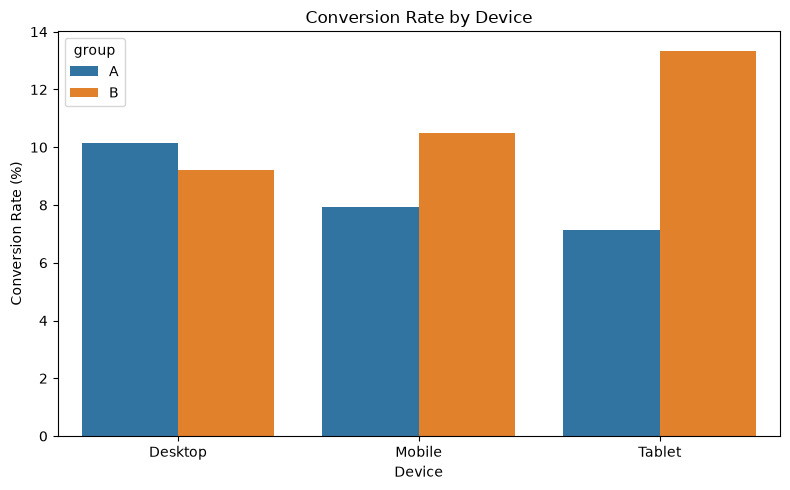

In [19]:
device_conversion = (
    df.groupby(["device", "group"])["purchases"]
    .mean()
    .mul(100)
    .reset_index(name="conversion_rate")
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=device_conversion,
    x="device",
    y="conversion_rate",
    hue="group"
)

plt.title("Conversion Rate by Device")
plt.xlabel("Device")
plt.ylabel("Conversion Rate (%)")

plt.tight_layout()
plt.savefig("../data/device_conversion.png", dpi=150)
plt.show()

In [20]:
contingency_table = pd.crosstab(
    df["group"],
    df["purchases"]
)

chi2_stat, chi2_p_value, dof, expected = (
    stats.chi2_contingency(contingency_table)
)

print("Contingency table:")
display(contingency_table)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"P-value: {chi2_p_value:.6f}")
print(f"Degrees of freedom: {dof}")

Contingency table:


purchases,0,1
group,,
A,4643,433
B,4412,512


Chi-square statistic: 9.9721
P-value: 0.001589
Degrees of freedom: 1


In [21]:
import sqlite3

connection = sqlite3.connect("../data/ab_testing.db")

df.to_sql(
    "ab_test_users",
    connection,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully.")

SQLite database created successfully.


In [22]:
query = """
SELECT
    "group",
    COUNT(DISTINCT user_id) AS total_users,
    SUM(purchases) AS total_purchases,
    ROUND(
        100.0 * SUM(purchases) / COUNT(DISTINCT user_id),
        2
    ) AS conversion_rate_pct
FROM ab_test_users
GROUP BY "group";
"""

display(pd.read_sql_query(query, connection))

,group,total_users,total_purchases,conversion_rate_pct
0,A,5076,433,8.53
1,B,4924,512,10.40


In [23]:
query = """
SELECT
    "group",
    COUNT(DISTINCT user_id) AS total_users,
    SUM(purchases) AS total_purchases,
    ROUND(
        100.0 * SUM(purchases) / COUNT(DISTINCT user_id),
        2
    ) AS conversion_rate_pct
FROM ab_test_users
GROUP BY "group";
"""

display(pd.read_sql_query(query, connection))

,group,total_users,total_purchases,conversion_rate_pct
0,A,5076,433,8.53
1,B,4924,512,10.40


In [24]:
query = """
SELECT
    "group",
    ROUND(SUM(revenue), 2) AS total_revenue,
    ROUND(AVG(revenue), 2) AS revenue_per_user,
    ROUND(AVG(visits), 2) AS average_visits
FROM ab_test_users
GROUP BY "group";
"""

display(pd.read_sql_query(query, connection))

,group,total_revenue,revenue_per_user,average_visits
0,A,540659.18,106.51,5.56
1,B,626834.34,127.30,5.56


In [25]:
query = """
SELECT
    device,
    "group",
    COUNT(*) AS total_users,
    SUM(purchases) AS purchasers,
    ROUND(100.0 * AVG(purchases), 2) AS conversion_rate_pct
FROM ab_test_users
GROUP BY device, "group"
ORDER BY device, "group";
"""

display(pd.read_sql_query(query, connection))

,device,group,total_users,purchasers,conversion_rate_pct
0,Desktop,A,1537,156,10.15
1,Desktop,B,1497,138,9.22
2,Mobile,A,3020,240,7.95
3,Mobile,B,2925,307,10.50
4,Tablet,A,519,37,7.13
5,Tablet,B,502,67,13.35


In [26]:
connection.close()

In [27]:
# Save group-level KPI results
summary.to_csv(
    "../data/experiment_results.csv",
    index=False
)

# Save device-level results
device_conversion.to_csv(
    "../data/device_conversion_results.csv",
    index=False
)

print("Results exported successfully.")

Results exported successfully.
